# PROPHET - TIME SERIES MODEL

In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
os.chdir("C:/Users/r.arriagadabaeza/OneDrive - Verisure/Escritorio/Pedidas Nati/Campaña bookings diciembre")

df = pd.read_csv('df.csv', sep=';')

In [3]:
import pandas as pd
import numpy as np
from prophet import Prophet
from matplotlib import pyplot as plt

c:\Users\r.arriagadabaeza\AppData\Local\anaconda3\envs\prophet-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [4]:
df["FECHA"] = pd.to_datetime(
    df["FECHA"],
    dayfirst=True,
    errors="raise"
)

In [5]:
# Parsear fecha
df["FECHA"] = pd.to_datetime(df["FECHA"])

# Normalizar textos
df["REGION"] = df["REGION"].str.strip().str.upper()
df["PUSH_PULL"] = df["PUSH_PULL"].str.upper()

In [6]:
df["REGION"] = (
    df["REGION"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df["PUSH_PULL"] = (
    df["PUSH_PULL"]
    .astype(str)
    .str.strip()
    .str.upper()
)

In [7]:
CONTROL_REGIONS = [
    "O’HIGGINS",
    "VALPARAISO",
    "METROPOLITANA"
]

VARIABLE_REGIONS = [
    "COQUIMBO",
    "ARAUCANIA",
    "LOS LAGOS",
    "LOS RIOS",
    "NUBLE",
    "BIOBIO",
    "MAULE"
]

In [8]:
def build_daily_series(df):
    return (
        df.groupby("FECHA")
          .size()
          .reset_index(name="y")
          .rename(columns={"FECHA": "ds"})
          .sort_values("ds")
    )


In [9]:
def prophet_impact_analysis(
    df,
    start_campaign="2025-12-03",
    end_campaign="2025-12-27"
):
    start_campaign = pd.to_datetime(start_campaign)
    end_campaign = pd.to_datetime(end_campaign)

    # Serie diaria
    ts = build_daily_series(df)

    # Split pre-campaign
    ts_train = ts[ts["ds"] < start_campaign]

    # Modelo Prophet
    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False
    )
    model.fit(ts_train)

    # Forecast hasta fin campaña
    future = model.make_future_dataframe(
        periods=(end_campaign - ts_train["ds"].max()).days
    )
    forecast = model.predict(future)

    # Merge real vs forecast
    impact_df = (
        ts.merge(
            forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
            on="ds",
            how="left"
        )
    )

    # Periodo campaña
    impact_df["is_campaign"] = (
        (impact_df["ds"] >= start_campaign) &
        (impact_df["ds"] <= end_campaign)
    )

    # Impacto diario
    impact_df["impact"] = impact_df["y"] - impact_df["yhat"]

    return impact_df


In [10]:
df_control_all = df[df["REGION"].isin(CONTROL_REGIONS)]
impact_control_all = prophet_impact_analysis(df_control_all)


17:54:05 - cmdstanpy - INFO - Chain [1] start processing
17:54:07 - cmdstanpy - INFO - Chain [1] done processing


In [11]:
df_variable_all = df[df["REGION"].isin(VARIABLE_REGIONS)]
impact_variable_all = prophet_impact_analysis(df_variable_all)


17:54:29 - cmdstanpy - INFO - Chain [1] start processing
17:54:29 - cmdstanpy - INFO - Chain [1] done processing


In [12]:
df_control_pull = df_control_all[df_control_all["PUSH_PULL"] == "PULL"]
impact_control_pull = prophet_impact_analysis(df_control_pull)

17:54:40 - cmdstanpy - INFO - Chain [1] start processing
17:54:40 - cmdstanpy - INFO - Chain [1] done processing


In [13]:
df_variable_pull = df_variable_all[df_variable_all["PUSH_PULL"] == "PULL"]
impact_variable_pull = prophet_impact_analysis(df_variable_pull)


17:54:44 - cmdstanpy - INFO - Chain [1] start processing
17:54:44 - cmdstanpy - INFO - Chain [1] done processing


In [14]:
def impact_summary(impact_df):
    campaign = impact_df[impact_df["is_campaign"]]

    return {
        "real_total": campaign["y"].sum(),
        "counterfactual_total": campaign["yhat"].sum(),
        "absolute_impact": campaign["impact"].sum(),
        "relative_impact_pct": campaign["impact"].sum() / campaign["yhat"].sum()
    }


In [15]:
summary_variable_pull = impact_summary(impact_variable_pull)
summary_variable_pull


{'real_total': 296,
 'counterfactual_total': 193.49674946871994,
 'absolute_impact': 102.50325053128006,
 'relative_impact_pct': 0.5297414598060233}

In [16]:
def plot_impact(impact_df, title):
    plt.figure(figsize=(14,6))
    plt.plot(impact_df["ds"], impact_df["y"], label="Real")
    plt.plot(impact_df["ds"], impact_df["yhat"], label="Contrafactual", linestyle="--")
    plt.axvspan(
        impact_df["ds"].min(),
        impact_df["ds"].max(),
        alpha=0.05
    )
    plt.title(title)
    plt.legend()
    plt.show()


In [17]:
def summarize_model(impact_df, model_name):
    campaign_df = impact_df[impact_df["is_campaign"]]

    expected = campaign_df["yhat"].sum()
    real = campaign_df["y"].sum()
    diff = real - expected
    lift_pct = diff / expected if expected != 0 else np.nan

    return {
        "modelo": model_name,
        "esperado_sin_campaña": round(expected, 0),
        "real_generado": int(real),
        "impacto_absoluto": int(diff),
        "impacto_%": round(lift_pct * 100, 2)
    }


In [18]:
summary_rows = []

summary_rows.append(
    summarize_model(
        impact_control_all,
        "Control – Todos los bookings"
    )
)

summary_rows.append(
    summarize_model(
        impact_variable_all,
        "Variable – Todos los bookings"
    )
)

summary_rows.append(
    summarize_model(
        impact_control_pull,
        "Control – Solo PULL"
    )
)

summary_rows.append(
    summarize_model(
        impact_variable_pull,
        "Variable – Solo PULL"
    )
)

impact_summary_df = pd.DataFrame(summary_rows)


In [22]:
impact_summary_df


,modelo,esperado_sin_campaña,real_generado,impacto_absoluto,impacto_%
0,Control – Todos los bookings,1003.0,1045,41,4.15
1,Variable – Todos los bookings,400.0,498,97,24.48
2,Control – Solo PULL,588.0,654,66,11.27
3,Variable – Solo PULL,193.0,296,102,52.97


In [ ]:
def plot_real_vs_counterfactual(
    impact_df,
    title,
    start_campaign="2025-12-03",
    end_campaign="2025-12-27"
):
    start_campaign = pd.to_datetime(start_campaign)
    end_campaign = pd.to_datetime(end_campaign)

    plt.figure(figsize=(15,6))

    plt.plot(
        impact_df["ds"],
        impact_df["y"],
        label="Real",
        linewidth=2
    )

    plt.plot(
        impact_df["ds"],
        impact_df["yhat"],
        linestyle="--",
        label="Esperado sin campaña"
    )

    plt.fill_between(
        impact_df["ds"],
        impact_df["yhat_lower"],
        impact_df["yhat_upper"],
        alpha=0.2,
        label="Intervalo esperado"
    )

    plt.axvspan(
        start_campaign,
        end_campaign,
        alpha=0.15,
        label="Periodo campaña"
    )

    plt.title(title)
    plt.xlabel("Fecha")
    plt.ylabel("Bookings diarios")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
def plot_daily_impact(
    impact_df,
    title,
    start_campaign="2025-12-03",
    end_campaign="2025-12-27"
):
    start_campaign = pd.to_datetime(start_campaign)
    end_campaign = pd.to_datetime(end_campaign)

    plt.figure(figsize=(15,5))

    plt.plot(
        impact_df["ds"],
        impact_df["impact"],
        label="Impacto diario",
        linewidth=2
    )

    plt.axhline(0, linestyle="--")

    plt.axvspan(
        start_campaign,
        end_campaign,
        alpha=0.15,
        label="Periodo campaña"
    )

    plt.title(title)
    plt.xlabel("Fecha")
    plt.ylabel("Δ Bookings")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
def plot_cumulative_impact(
    impact_df,
    title,
    start_campaign="2025-12-03",
    end_campaign="2025-12-27"
):
    start_campaign = pd.to_datetime(start_campaign)
    end_campaign = pd.to_datetime(end_campaign)

    df = impact_df.copy()
    df["impact_cum"] = df["impact"].cumsum()

    plt.figure(figsize=(15,5))

    plt.plot(
        df["ds"],
        df["impact_cum"],
        linewidth=2,
        label="Impacto acumulado"
    )

    plt.axhline(0, linestyle="--")

    plt.axvspan(
        start_campaign,
        end_campaign,
        alpha=0.15,
        label="Periodo campaña"
    )

    plt.title(title)
    plt.xlabel("Fecha")
    plt.ylabel("Bookings acumulados")
    plt.legend()
    plt.tight_layout()
    plt.show()


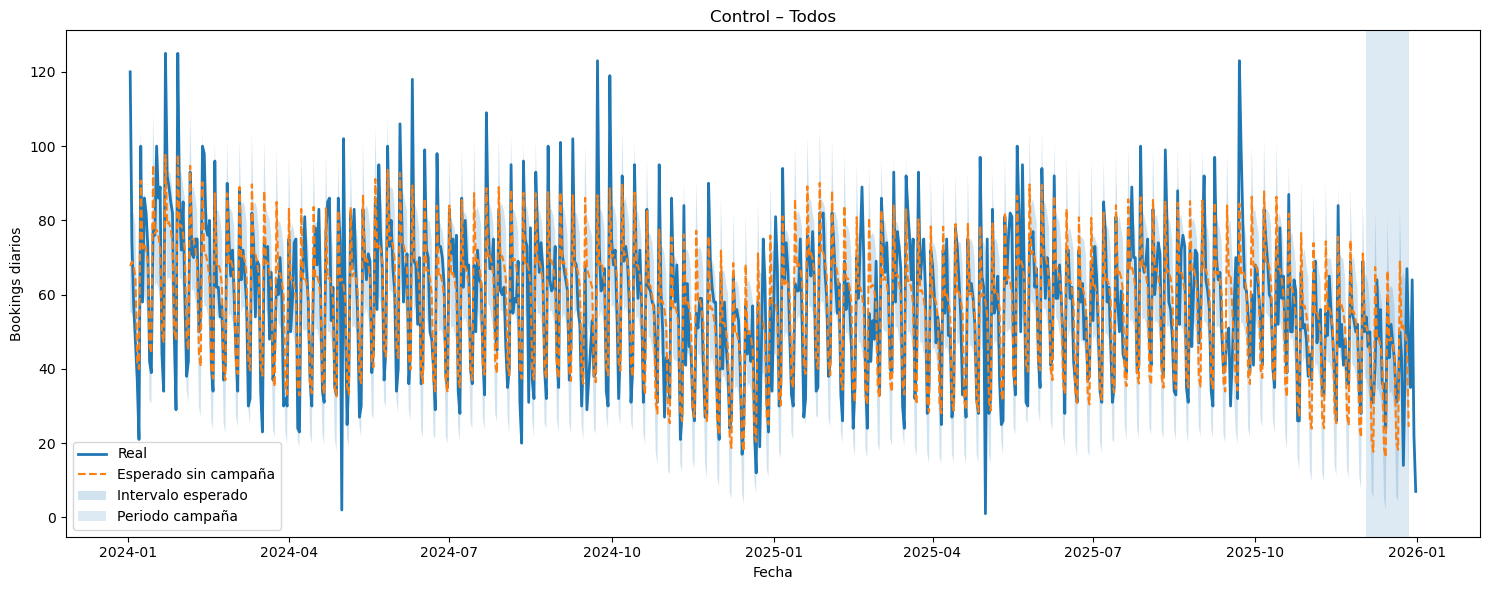

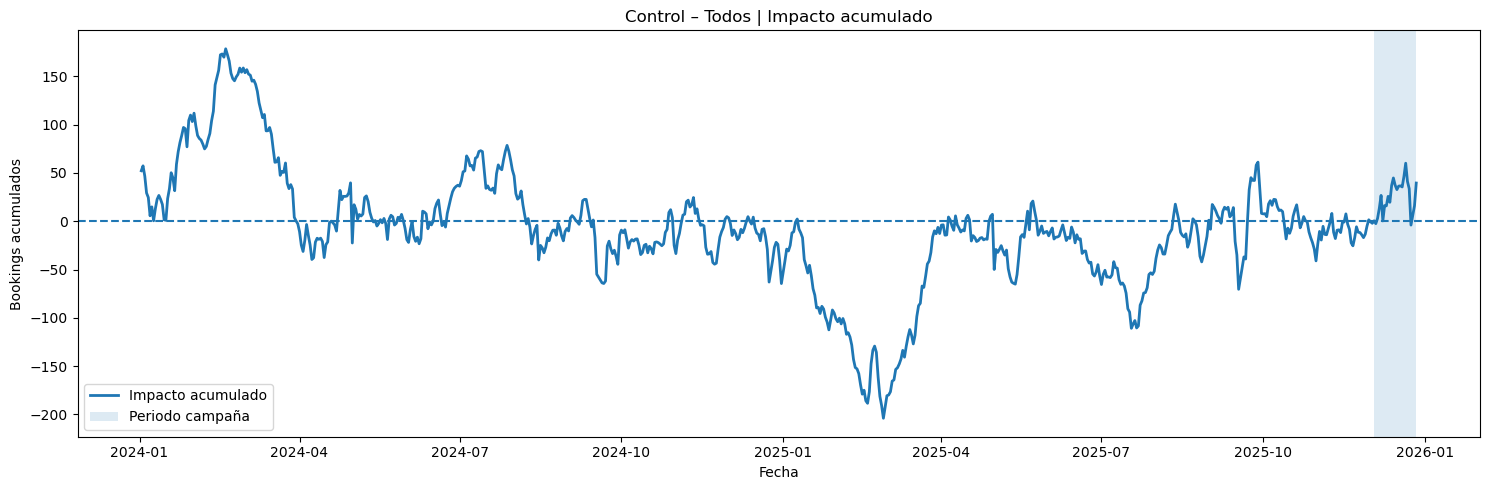

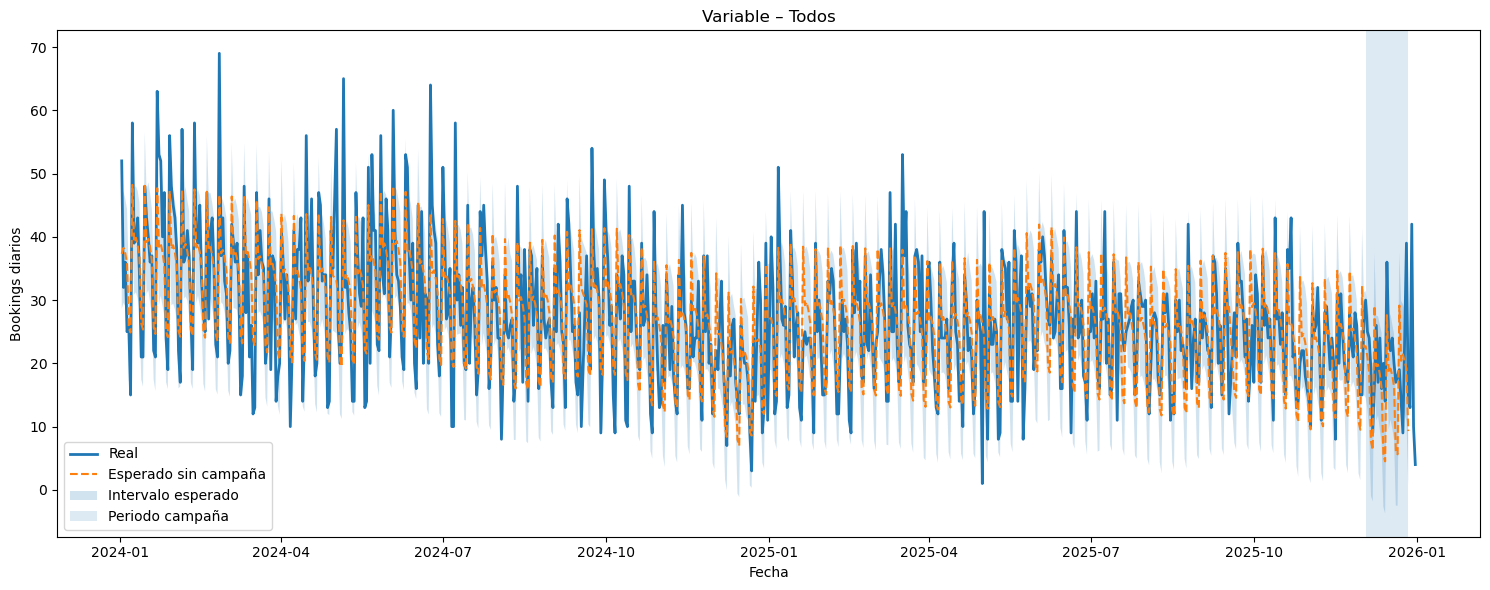

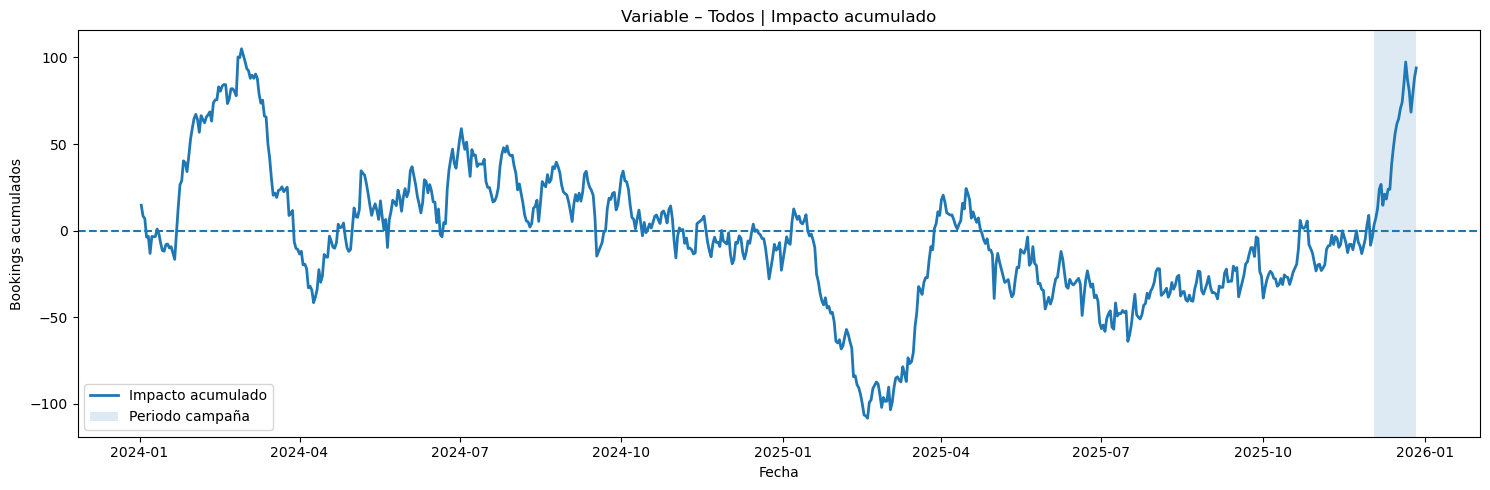

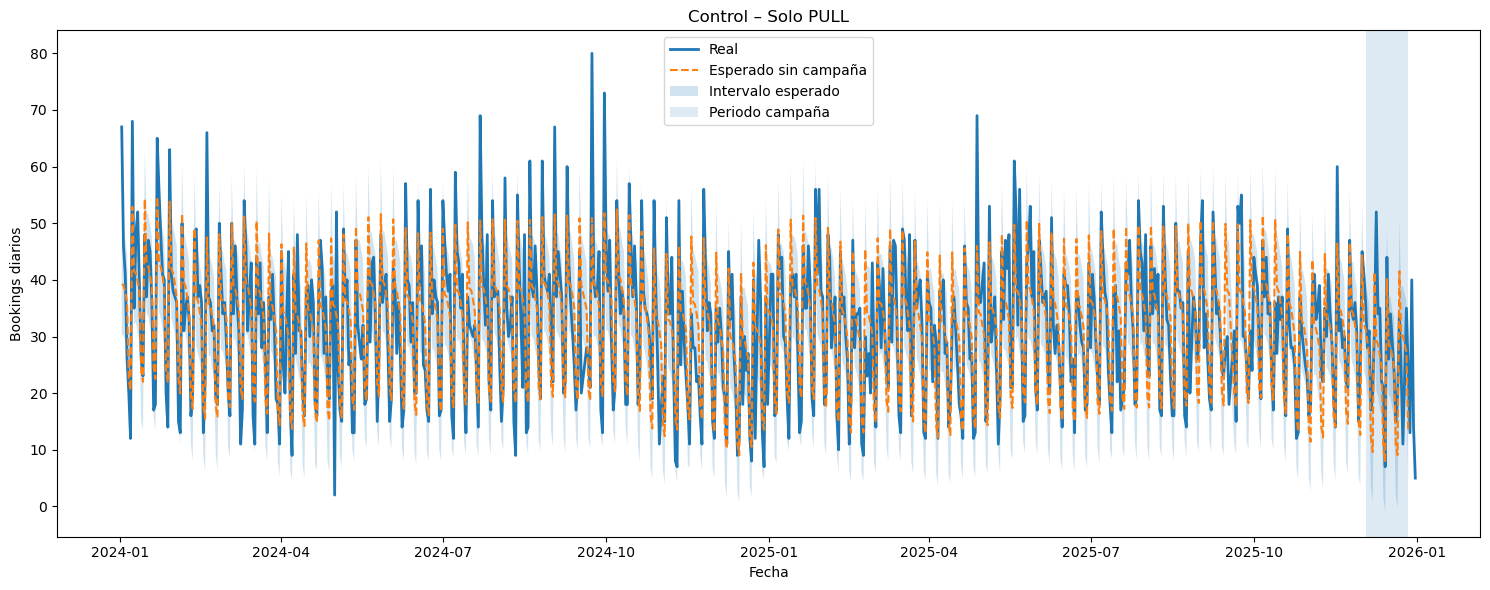

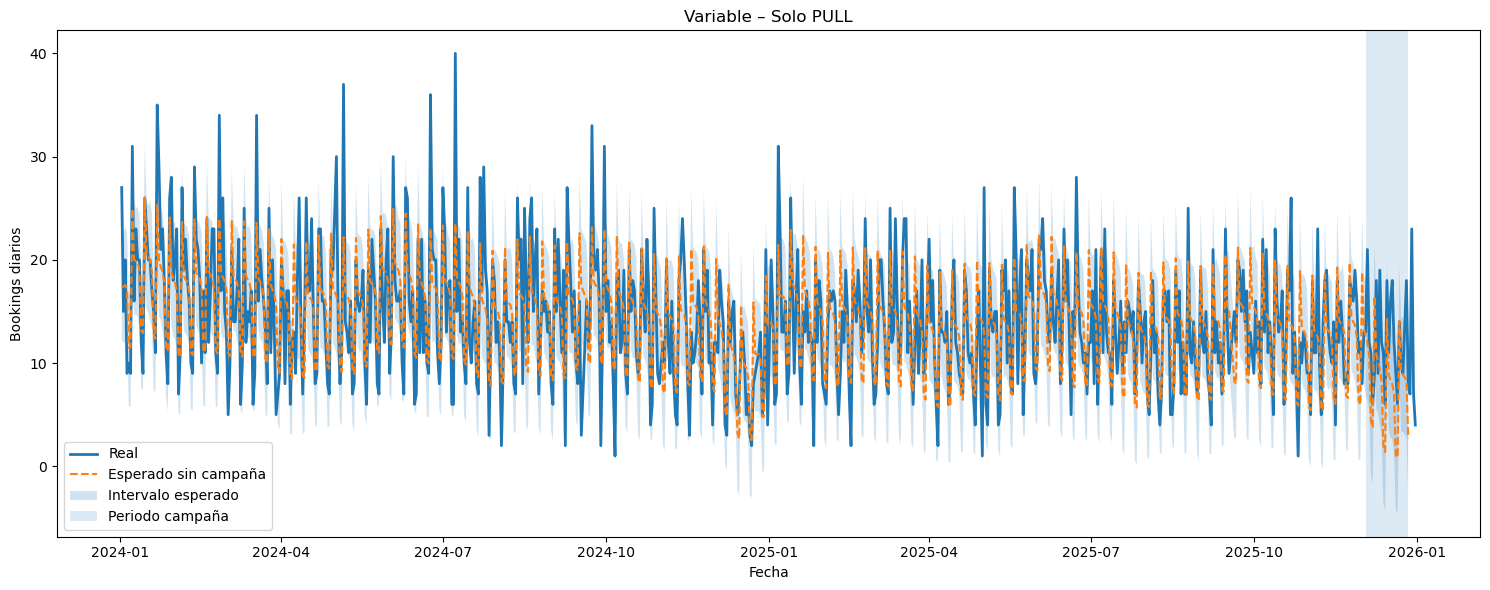

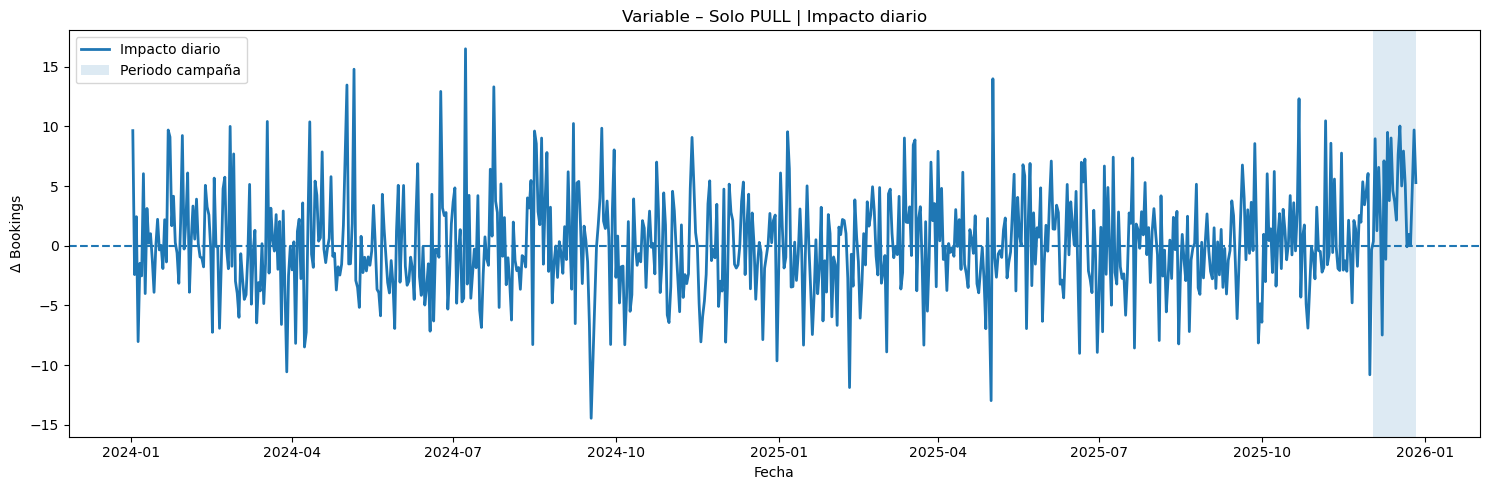

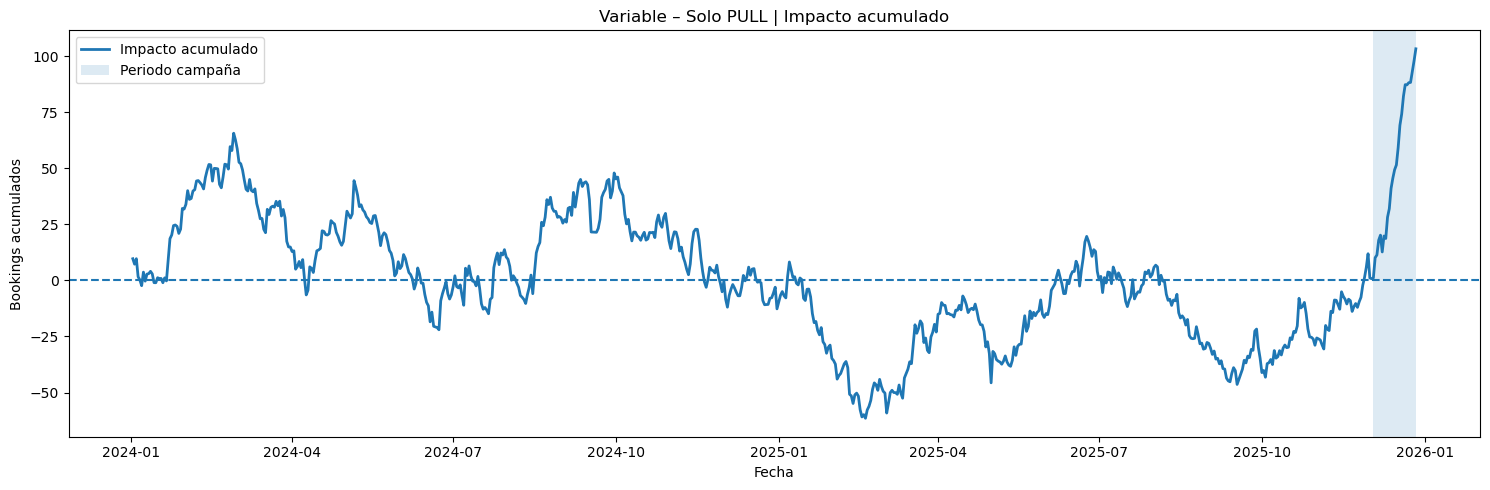

In [29]:
# 1. Control – Todos
plot_real_vs_counterfactual(impact_control_all, "Control – Todos")
plot_cumulative_impact(impact_control_all, "Control – Todos | Impacto acumulado")

# 2. Variable – Todos
plot_real_vs_counterfactual(impact_variable_all, "Variable – Todos")
plot_cumulative_impact(impact_variable_all, "Variable – Todos | Impacto acumulado")

# 3. Control – PULL
plot_real_vs_counterfactual(impact_control_pull, "Control – Solo PULL")

# 4. Variable – PULL (la estrella)
plot_real_vs_counterfactual(impact_variable_pull, "Variable – Solo PULL")
plot_daily_impact(impact_variable_pull, "Variable – Solo PULL | Impacto diario")
plot_cumulative_impact(impact_variable_pull, "Variable – Solo PULL | Impacto acumulado")
